# 02. Czyszczenie danych, integracja i zapis do bazy SQL

**Etap 3 projektu:** integracja zbiorów i baza danych

Notebook przedstawia kolejne kroki przetwarzania danych surowych (notebook 01) do postaci jednego
zbioru godzinowego zapisanego w relacyjnej bazie danych SQLite (`data/kse.db`). Kod przetwarzania
znajduje się w module `src/przetwarzanie.py`, a obsługa bazy – w module `src/baza_danych.py`.

Główne problemy integracji (rozdział 7 koncepcji) i przyjęte rozwiązania:

| Problem | Rozwiązanie |
|---|---|
| różne strefy czasowe (czas lokalny z dobą handlową 1–24, UTC) | wspólny klucz: początek godziny w UTC |
| doby 23- i 25-godzinne przy zmianie czasu | praca w UTC – brak duplikatów i luk |
| różna rozdzielczość (15 min i 1 h) | średnia godzinowa (moc w MW, cena w PLN/MWh) |
| dwa źródła PSE i cen (granica 14.06.2024) | złączenie szeregów na granicy |
| ceny w EUR przed 14.06.2024 | przeliczenie po średnim kursie NBP |
| 10 lokalizacji pogodowych | średnia ważona dla Polski |
| pojedyncze braki | interpolacja liniowa luk do 3 godzin |

In [1]:
import sys
import warnings
from pathlib import Path

# ostrzeżenie biblioteki requests o wersjach zależności nie wpływa na wyniki
warnings.filterwarnings("ignore", message=".*doesn't match a supported version")

# katalog projektu (nadrzędny względem notebooks/) – dostęp do modułów src
sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import wykresy
from src.wykresy import format_polski

wykresy.ustaw_styl()

In [2]:
from src import baza_danych, przetwarzanie
from src.konfiguracja import REFORMA_RB, STREFA_LOKALNA

granica = pd.Timestamp(REFORMA_RB, tz=STREFA_LOKALNA).tz_convert("UTC")

## 1. Dane PSE (Z1)

### 1.1. Doba handlowa a czas UTC

W archiwum PSE czas opisany jest datą i numerem godziny doby handlowej. Funkcja
`_czas_z_doby_handlowej()` zamienia północ czasu lokalnego na UTC i dodaje numer kolejnego wiersza
doby. Dzięki temu w dniu zmiany czasu z letniego na zimowy (29.10.2023) powtórzona godzina
(w raporcie PSE oznaczona jako „2A”) oraz kolejna godzina, obie rozpoczynające się lokalnie o 02:00,
otrzymują różne znaczniki UTC:

In [3]:
wyk = przetwarzanie._wczytaj_archiwum("PL_WYK_KSE")
zmiana_czasu = wyk[wyk["Data"] == "2023-10-29"][["Data", "Godzina", "czas_utc"]].head(5)
zmiana_czasu.assign(czas_lokalny=zmiana_czasu["czas_utc"].dt.tz_convert(STREFA_LOKALNA))

,Data,Godzina,czas_utc,czas_lokalny
15983,2023-10-29,1,2023-10-28 22:00:00+00:00,2023-10-29 00:00:00+02:00
15984,2023-10-29,2,2023-10-28 23:00:00+00:00,2023-10-29 01:00:00+02:00
15985,2023-10-29,2A,2023-10-29 00:00:00+00:00,2023-10-29 02:00:00+02:00
15986,2023-10-29,3,2023-10-29 01:00:00+00:00,2023-10-29 02:00:00+01:00
15987,2023-10-29,4,2023-10-29 02:00:00+00:00,2023-10-29 03:00:00+01:00


### 1.2. Agregacja danych 15-minutowych do godzin

W danych z API pole `dtime_utc` oznacza koniec okresu 15-minutowego. Po przesunięciu na początek
okresu i zaokrągleniu w dół do pełnej godziny cztery kolejne okresy tworzą jedną godzinę,
a wartość godzinowa jest ich średnią (moc średnia w MW).

In [4]:
api = przetwarzanie._wczytaj_api("kse-load")
godzina = pd.Timestamp("2025-01-15 12:00", tz="UTC")
display(api.loc[api["czas_utc"] == godzina, ["dtime_utc", "period_utc", "czas_utc", "load_actual"]])
print(f"Średnia z czterech okresów: {api.loc[api['czas_utc'] == godzina, 'load_actual'].mean():.3f} MW")

,dtime_utc,period_utc,czas_utc,load_actual
20696,2025-01-15 12:15:00,12:00 - 12:15,2025-01-15 12:00:00+00:00,"24 803,26"
20697,2025-01-15 12:30:00,12:15 - 12:30,2025-01-15 12:00:00+00:00,"24 641,65"
20698,2025-01-15 12:45:00,12:30 - 12:45,2025-01-15 12:00:00+00:00,"24 391,23"
20699,2025-01-15 13:00:00,12:45 - 13:00,2025-01-15 12:00:00+00:00,"24 057,95"


Średnia z czterech okresów: 24473.524 MW


### 1.3. Połączenie archiwum i API

Funkcja `przygotuj_pse()` wykonuje powyższe kroki dla wszystkich raportów i łączy oba źródła na
granicy 14.06.2024 r.

In [5]:
pse = przetwarzanie.przygotuj_pse()
print(f"Liczba godzin: {len(pse)}, zakres: {pse.index.min()} – {pse.index.max()}")
pse.describe().T

Liczba godzin: 41615, zakres: 2021-12-31 23:00:00+00:00 – 2026-09-30 21:00:00+00:00


,count,mean,std,min,25%,50%,75%,max
zapotrzebowanie_mw,"41 615,00","18 752,90","3 221,19","10 595,80","16 164,39","18 809,14","21 087,39","28 303,88"
generacja_wiatr_mw,"41 615,00","2 442,84","1 906,43","14,74","918,62","1 913,05","3 561,83","8 897,35"
generacja_pv_mw,"41 615,00","1 905,09","2 888,97","0,00","0,00","161,21","3 020,49","14 368,42"
prognoza_sieci_pse_mw,"21 479,00","16 963,11","2 992,03","8 541,00","14 801,00","16 798,00","19 021,00","25 038,00"
prognoza_pse_mw,"20 136,00","18 266,24","3 104,67","10 400,00","15 737,50","18 450,00","20 437,50","27 250,00"


### 1.4. Porównywalność prognozy PSE

Archiwalny raport „plan dobowy” zawiera wielkość *prognozowane zapotrzebowanie sieci*, a od
14.06.2024 r. API publikuje prognozę *krajowego zapotrzebowania na moc*. Poniższy wykres przedstawia
średnią miesięczną różnicę między zapotrzebowaniem rzeczywistym a każdą z tych wielkości.

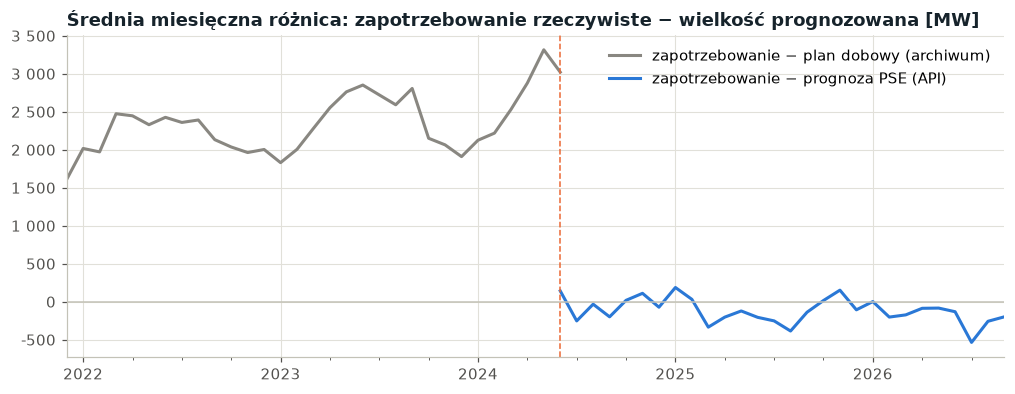

,średnia różnica [MW]
zapotrzebowanie − plan dobowy (archiwum),"2 347,88"
zapotrzebowanie − prognoza PSE (API),"-118,30"


In [6]:
roznice = pd.DataFrame({
    "zapotrzebowanie − plan dobowy (archiwum)": pse["zapotrzebowanie_mw"] - pse["prognoza_sieci_pse_mw"],
    "zapotrzebowanie − prognoza PSE (API)": pse["zapotrzebowanie_mw"] - pse["prognoza_pse_mw"],
}).resample("MS").mean()

fig, ax = plt.subplots(figsize=(11, 3.8))
roznice.plot(ax=ax, color=[wykresy.TUSZ_WYCISZONY, wykresy.NIEBIESKI], linewidth=2)
ax.axhline(0, color=wykresy.OS, linewidth=1)
ax.axvline(granica, color=wykresy.POMARANCZOWY, linestyle="--", linewidth=1)
ax.set_title("Średnia miesięczna różnica: zapotrzebowanie rzeczywiste − wielkość prognozowana [MW]")
ax.set_xlabel("")
format_polski(ax)
plt.show()
roznice.mean().rename("średnia różnica [MW]").to_frame()

Archiwalna wielkość jest systematycznie niższa od zapotrzebowania – średnio o ok. 2,3 GW,
w poszczególnych miesiącach o 1,6–3,3 GW – co wskazuje na inny zakres bilansowy tej wielkości,
a nie na błąd prognozy. Prognoza z API różni się od zapotrzebowania średnio o ok. 120 MW
(ok. 0,6% poziomu zapotrzebowania). Dlatego:

* archiwalna wielkość zapisywana jest w osobnej kolumnie `prognoza_sieci_pse_mw`,
* kolumna `prognoza_pse_mw` zawiera wyłącznie prognozę porównywalną (od 14.06.2024 r.),
* porównanie modelu z prognozą PSE wykonywane jest na danych z 2026 r. (notebook 04).

## 2. Miks energetyczny (Z2)

Dane 15-minutowe uśredniane są do godzin, a typy źródeł bez generacji w całym okresie (odpady – B17)
są pomijane. Każdy kod źródła
przypisany jest do kategorii (OZE, konwencjonalne, magazynowanie) i grupy prezentowanej na wykresach.

In [7]:
miks = przetwarzanie.przygotuj_miks()
print(f"Rekordy godzinowe miksu: {len(miks)}")
zrodla = przetwarzanie.ZRODLA.merge(
    miks.groupby("kod_zrodla")["generacja_mw"].mean().rename("srednia_generacja_mw"),
    left_on="kod_zrodla", right_index=True, how="left")
zrodla.sort_values("srednia_generacja_mw", ascending=False)

Rekordy godzinowe miksu: 503102


,kod_zrodla,nazwa_zrodla,kategoria,grupa,srednia_generacja_mw
0,B05,Węgiel kamienny,konwencjonalne,Węgiel kamienny,"6 989,32"
1,B02,Węgiel brunatny,konwencjonalne,Węgiel brunatny,"3 854,15"
8,B19,Wiatr na lądzie,OZE,Wiatr,"2 439,00"
10,B16,Fotowoltaika,OZE,Fotowoltaika,"1 904,78"
2,B04,Gaz ziemny,konwencjonalne,Gaz ziemny,"1 778,57"
5,B20,Pozostałe,konwencjonalne,Pozostałe,"596,79"
11,B01,Biomasa,OZE,Biomasa,"261,94"
4,B06,Olej opałowy,konwencjonalne,Pozostałe,"224,65"
12,B11,Elektrownie wodne przepływowe,OZE,Woda i magazyny,"150,81"
7,B10,Elektrownie szczytowo-pompowe,magazynowanie,Woda i magazyny,"146,46"


Na podstawie formatu długiego wyznaczane są agregaty godzinowe dołączane do zbioru głównego:
generacja całkowita (bez elektrowni szczytowo-pompowych, które magazynują energię), udział OZE
i udział węgla w generacji.

## 3. Ceny energii (Z3)

Do 13.06.2024 r. cena w EUR/MWh przeliczana jest po kursie NBP z dnia dostawy (w dni bez notowań –
po ostatnim opublikowanym kursie, funkcja `merge_asof`). Od 14.06.2024 r. wykorzystywana jest cena
SDAC w PLN publikowana przez PSE.

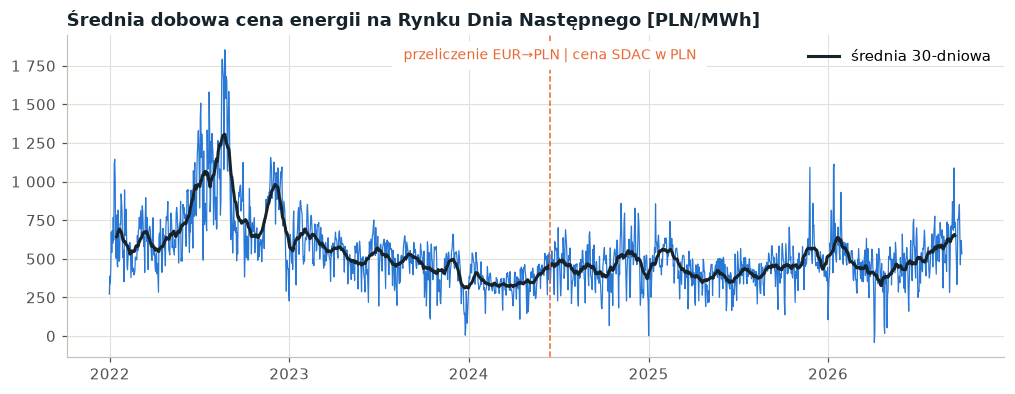

,cena_pln_mwh
count,"41 615,00"
mean,"531,58"
std,"295,55"
min,"-1 998,41"
25%,"388,79"
50%,"487,31"
75%,"634,78"
max,"3 678,13"


In [8]:
ceny = przetwarzanie.przygotuj_ceny()
dobowe = ceny["cena_pln_mwh"].resample("D").mean()

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(dobowe.index, dobowe, color=wykresy.NIEBIESKI, linewidth=0.8)
ax.plot(dobowe.rolling(30, center=True).mean(), color=wykresy.TUSZ, linewidth=2, label="średnia 30-dniowa")
ax.axvline(granica, color=wykresy.POMARANCZOWY, linestyle="--", linewidth=1)
ax.text(granica, ax.get_ylim()[1] * 0.92, " przeliczenie EUR→PLN | cena SDAC w PLN ",
        color=wykresy.POMARANCZOWY, ha="center", fontsize=9, backgroundcolor="white")
ax.set_title("Średnia dobowa cena energii na Rynku Dnia Następnego [PLN/MWh]")
ax.legend(loc="upper right")
format_polski(ax)
plt.show()
ceny["cena_pln_mwh"].describe().to_frame()

Szereg nie wykazuje skoku na granicy źródeł, co potwierdza poprawność przeliczenia walut.
Widoczny jest kryzys cenowy 2022 r. oraz występowanie cen ujemnych (minimum szeregu).

## 4. Pogoda (Z4)

Wartości ogólnopolskie wyznaczane są jako średnie ważone:

* temperatura – ważona liczbą ludności województwa (zapotrzebowanie zależy od liczby odbiorców),
* prędkość wiatru – ważona udziałem województwa w mocy zainstalowanej farm wiatrowych,
* promieniowanie i zachmurzenie – średnia arytmetyczna.

In [9]:
stacje, polska = przetwarzanie.przygotuj_pogode()
srednie_proste = stacje.groupby("czas_utc")[["temperatura_c", "wiatr_100m_ms"]].mean()
pd.DataFrame({
    "średnia ważona": polska[["temperatura_c", "wiatr_100m_ms"]].mean(),
    "średnia arytmetyczna": srednie_proste.mean(),
    "korelacja obu średnich": polska[["temperatura_c", "wiatr_100m_ms"]].corrwith(srednie_proste),
})

,średnia ważona,średnia arytmetyczna,korelacja obu średnich
temperatura_c,"10,56","10,47","1,00"
wiatr_100m_ms,"6,10","5,88","0,98"


In [10]:
# średnia roczna temperatura w poszczególnych lokalizacjach (pełne lata)
from src.konfiguracja import LOKALIZACJE

nazwy = {m["id"]: m["nazwa"] for m in LOKALIZACJE}
roczne = (stacje.assign(rok=stacje["czas_utc"].dt.tz_convert(STREFA_LOKALNA).dt.year,
                        miasto=stacje["id_stacji"].map(nazwy))
          .query("2022 <= rok <= 2025")
          .pivot_table(index="miasto", columns="rok", values="temperatura_c", aggfunc="mean"))
roczne.sort_values(2025)

rok,2022,2023,2024,2025
miasto,,,,
Białystok,"8,56","9,77","10,46","9,31"
Łódź,"9,28","10,21","11,10","9,60"
Gdańsk,"9,59","10,00","10,81","9,76"
Kraków,"9,84","10,73","11,54","10,00"
Rzeszów,"9,68","10,50","11,35","10,04"
Szczecin,"10,29","10,46","11,37","10,07"
Katowice,"9,76","10,46","11,31","10,08"
Warszawa,"9,75","10,63","11,48","10,15"
Wrocław,"10,72","11,17","11,82","10,16"


Ważenie wiatru przesuwa średnią w kierunku województw północnych i zachodnich, w których
zlokalizowana jest większość farm wiatrowych – średnia ważona prędkość wiatru jest wyższa od
arytmetycznej. Pomiary z poszczególnych lokalizacji zachowywane są w osobnej tabeli faktów
na potrzeby wizualizacji przestrzennej.

## 5. Integracja i kalendarz (Z5)

Funkcja `zbuduj_zbior()` tworzy pełną siatkę godzin UTC odpowiadającą okresowi analizy, dołącza do
niej wszystkie źródła, uzupełnia krótkie luki interpolacją, wyznacza zapotrzebowanie netto
(zapotrzebowanie − wiatr − PV) i zmienne kalendarzowe (w czasie lokalnym), a następnie zapisuje
wynik do bazy danych. Baza została już utworzona przez `run_pipeline.py`, dlatego zbiór
odczytywany jest z widoku `v_kse_godzinowy`.

In [11]:
zbior = baza_danych.wczytaj_zbior()
print(f"Zbiór godzinowy: {zbior.shape[0]} wierszy × {zbior.shape[1]} kolumn")
zbior.head(2).T

Zbiór godzinowy: 41615 wierszy × 25 kolumn


czas_utc,2021-12-31 23:00:00+00:00,2022-01-01 00:00:00+00:00
zapotrzebowanie_mw,"14 910,84","14 438,25"
generacja_wiatr_mw,"4 255,65","4 243,99"
generacja_pv_mw,"0,00","0,00"
prognoza_sieci_pse_mw,"13 301,00","13 072,00"
prognoza_pse_mw,NaN,NaN
cena_pln_mwh,"270,88","226,55"
temperatura_c,"8,91","8,73"
wiatr_100m_ms,"10,58","10,05"
promieniowanie_wm2,"0,00","0,00"
zachmurzenie_proc,"100,00","100,00"


In [12]:
# liczba godzin w dobie czasu lokalnego – doby zmiany czasu mają 23 i 25 godzin, bez duplikatów i luk
godziny_w_dobie = zbior.groupby("data").size()
print(f"Unikalne znaczniki czasu: {zbior.index.is_unique}, "
      f"odstęp między godzinami zawsze 1 h: {(zbior.index.to_series().diff().dropna() == pd.Timedelta('1h')).all()}")
godziny_w_dobie.value_counts().rename("liczba dób")

Unikalne znaczniki czasu: True, odstęp między godzinami zawsze 1 h: True


24    1725
23       5
25       4
Name: liczba dób, dtype: int64

In [13]:
# zgodność zbioru w bazie z wynikiem przetwarzania (interpolacja zmienia tylko brakujące wartości)
for kolumna, zrodlo in [("zapotrzebowanie_mw", pse), ("generacja_pv_mw", pse), ("cena_pln_mwh", ceny)]:
    wspolne = zrodlo[kolumna].dropna().index.intersection(zbior.index)
    roznica = (zbior.loc[wspolne, kolumna] - zrodlo.loc[wspolne, kolumna]).abs().max()
    print(f"{kolumna}: maksymalna różnica = {roznica:.6f}")

zapotrzebowanie_mw: maksymalna różnica = 0.000000
generacja_pv_mw: maksymalna różnica = 0.000000
cena_pln_mwh: maksymalna różnica = 0.000000


Typ dnia wyznaczany jest według priorytetu: święto → weekend → dzień pomostowy → dzień roboczy.
Dzień pomostowy to dzień roboczy, który sąsiaduje z dniami wolnymi z obu stron
(np. piątek po czwartkowym święcie).

In [14]:
kalendarz = baza_danych.wczytaj("""
    SELECT typ_dnia, COUNT(*) AS liczba_dob
    FROM dim_kalendarz
    GROUP BY typ_dnia
    ORDER BY liczba_dob DESC
""")
pomostowe = baza_danych.wczytaj("""
    SELECT data, dzien_tygodnia_nazwa FROM dim_kalendarz WHERE typ_dnia = 'pomostowy' ORDER BY data
""")
display(kalendarz)
print("Dni pomostowe:", ", ".join(pomostowe["data"].dt.strftime("%d.%m.%Y") + " (" + pomostowe["dzien_tygodnia_nazwa"] + ")"))

,typ_dnia,liczba_dob
0,roboczy,1179
1,weekend,476
2,święto,62
3,pomostowy,17


Dni pomostowe: 07.01.2022 (piątek), 02.05.2022 (poniedziałek), 17.06.2022 (piątek), 31.10.2022 (poniedziałek), 02.05.2023 (wtorek), 09.06.2023 (piątek), 14.08.2023 (poniedziałek), 02.05.2024 (czwartek), 31.05.2024 (piątek), 16.08.2024 (piątek), 27.12.2024 (piątek), 02.05.2025 (piątek), 20.06.2025 (piątek), 10.11.2025 (poniedziałek), 02.01.2026 (piątek), 05.01.2026 (poniedziałek), 05.06.2026 (piątek)


## 6. Jakość danych

Raport jakości (tabela `jakosc_danych`) zawiera liczbę braków przed i po uzupełnieniu luk.

In [15]:
baza_danych.wczytaj("SELECT * FROM jakosc_danych").set_index("zmienna")

,liczba_godzin,braki_przed,braki_po,kompletnosc_proc
zmienna,,,,
zapotrzebowanie_mw,41615,0,0,"100,00"
generacja_wiatr_mw,41615,0,0,"100,00"
generacja_pv_mw,41615,0,0,"100,00"
prognoza_sieci_pse_mw,41615,20136,20136,"51,61"
prognoza_pse_mw,41615,21479,21479,"48,39"
cena_pln_mwh,41615,0,0,"100,00"
temperatura_c,41615,0,0,"100,00"
wiatr_100m_ms,41615,0,0,"100,00"
promieniowanie_wm2,41615,0,0,"100,00"


Wszystkie zmienne pomiarowe są kompletne w 100%. Braki w kolumnach prognoz PSE wynikają z opisanego
wyżej rozdzielenia dwóch wielkości na granicy 14.06.2024 r. i nie są uzupełniane.

## 7. Baza danych SQL

Struktura bazy zdefiniowana jest w plikach `sql/schemat.sql` (tabele wymiarów, faktów, wyników
analiz oraz widoki analityczne `v_*`) i `sql/widoki_powerbi.sql` (widoki raportowe `pbi_*`
odczytywane przez Power BI). Schemat odpowiada modelowi gwiazdy: tabele faktów łączą się
z wymiarami kluczami obcymi, a wspólnym kluczem czasu jest początek godziny w UTC.

In [16]:
obiekty = baza_danych.wczytaj("SELECT name AS nazwa, type AS typ FROM sqlite_master "
                              "WHERE type IN ('table', 'view') ORDER BY type, name")
obiekty["liczba_wierszy"] = [baza_danych.wczytaj(f"SELECT COUNT(*) AS n FROM {n}")["n"].iloc[0]
                             for n in obiekty["nazwa"]]
obiekty

,nazwa,typ,liczba_wierszy
0,dim_czas,table,41615
1,dim_godzina,table,24
2,dim_kalendarz,table,1734
3,dim_lokalizacja,table,10
4,dim_zrodlo,table,15
5,fakt_kse_godzinowy,table,41615
6,fakt_miks,table,500125
7,fakt_pogoda_stacje,table,416150
8,jakosc_danych,table,13
9,klastry_doby,table,3468


In [17]:
import re
from src.konfiguracja import KATALOG_SQL

schemat = (KATALOG_SQL / "schemat.sql").read_text(encoding="utf-8")
print(re.search(r"CREATE TABLE fakt_kse_godzinowy.*?\);", schemat, re.S).group())

CREATE TABLE fakt_kse_godzinowy (
    czas_utc                  TEXT PRIMARY KEY REFERENCES dim_czas (czas_utc),
    zapotrzebowanie_mw        REAL,
    generacja_wiatr_mw        REAL,
    generacja_pv_mw           REAL,
    prognoza_sieci_pse_mw     REAL,                   -- archiwalny plan dobowy PSE (do 13.06.2024)
    prognoza_pse_mw           REAL,                   -- prognoza zapotrzebowania PSE (od 14.06.2024)
    cena_pln_mwh              REAL,
    temperatura_c             REAL,                   -- średnia ważona liczbą ludności
    wiatr_100m_ms             REAL,                   -- średnia ważona mocą farm wiatrowych
    promieniowanie_wm2        REAL,
    zachmurzenie_proc         REAL,
    generacja_calkowita_mw    REAL,
    udzial_oze_proc           REAL,
    udzial_wegla_proc         REAL,
    zapotrzebowanie_netto_mw  REAL                    -- zapotrzebowanie − wiatr − PV
);


Przykład zapytania analitycznego łączącego tabelę faktów z wymiarami czasu i kalendarza –
średnie zapotrzebowanie i cena energii według roku i typu dnia:

In [18]:
baza_danych.wczytaj("""
    SELECT k.rok,
           k.typ_dnia,
           ROUND(AVG(f.zapotrzebowanie_mw)) AS srednie_zapotrzebowanie_mw,
           ROUND(AVG(f.cena_pln_mwh), 1)   AS srednia_cena_pln_mwh,
           ROUND(AVG(f.udzial_oze_proc), 1) AS sredni_udzial_oze_proc
    FROM fakt_kse_godzinowy AS f
    JOIN dim_czas AS c ON c.czas_utc = f.czas_utc
    JOIN dim_kalendarz AS k ON k.data = c.data
    GROUP BY k.rok, k.typ_dnia
    ORDER BY k.rok, srednie_zapotrzebowanie_mw DESC
""").pivot(index="typ_dnia", columns="rok", values="srednie_zapotrzebowanie_mw")

rok,2022,2023,2024,2025,2026
typ_dnia,,,,,
pomostowy,"17 962,00","16 092,00","16 469,00","15 695,00","17 891,00"
roboczy,"20 763,00","20 045,00","19 664,00","19 050,00","19 234,00"
weekend,"17 598,00","16 895,00","16 603,00","16 190,00","16 444,00"
święto,"15 556,00","15 009,00","15 058,00","14 776,00","14 858,00"


## Podsumowanie

* Dane z pięciu źródeł połączono w jeden zbiór godzinowy obejmujący 41 615 godzin
  (01.01.2022 – 30.09.2026) z kluczem czasu w UTC; doby zmiany czasu zachowują poprawną liczbę godzin.
* Zmienne pomiarowe są kompletne w 100% – pojedyncze krótkie luki uzupełniono interpolacją.
* Ustalono, że archiwalna prognoza PSE nie jest porównywalna z prognozą publikowaną od 14.06.2024 r.,
  co zdecydowało o wyborze roku 2026 jako zbioru testowego modelu.
* Wynik zapisano w relacyjnej bazie SQLite w schemacie gwiazdy (5 wymiarów, 3 tabele faktów,
  tabele wyników analiz i widoki), z której korzystają kolejne notebooki, aplikacja i raport Power BI.